# 🛡️ AIForensicNet V4 (Tri-Stream SOTA) — OwensLab/CommunityForensics (CVPR 2025)
### Deteksi Citra AI vs Real dengan Arsitektur Tri-Stream Ringkas (NPR + 2D-FFT + Spatial RGB)

---

## 📋 Keunggulan Arsitektur yang Disederhanakan
- **Dataset Tunggal Skala Besar ([OwensLab/CommunityForensics](https://huggingface.co/datasets/OwensLab/CommunityForensics) - CVPR 2025):** Mencakup ribuan generator AI komunitas & komersial (Diffusion, Flux, SDXL, Midjourney, GAN) vs citra fotografi/seni otentik.
- **Tri-Stream Early Fusion (Single Backbone ~2.93M Parameter):**
  1. **Forensic Filter Bank (15 Kanal):** Laplacian 3x3, Laplacian 5x5, DoG 5x5, Sobel Magnitude, dan **NPR (*Neighboring Pixel Relationships*, CVPR 2024)** murni bebas parameter.
  2. **2D-FFT Spectral Branch (32 Kanal):** Mengekstrak anomali frekuensi domain Fourier (`rfft2`).
  3. **Spatial RGB Stem (32 Kanal):** Mengekstrak tekstur visual dan koherensi pencahayaan.
- **100% Kompatibel dengan `app.py` (Streamlit):** Format bobot `state_dict`, dimensi layer, dan urutan kelas (`0 = AI-Generated`, `1 = Real`) langsung siap pakai di aplikasi tanpa ubahan kode.

In [ ]:
# @title 🛠️ 1. Persiapan Lingkungan & Hardware Acceleration
import os
import io
import time
import random
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
Image.MAX_IMAGE_PIXELS = None
warnings.simplefilter('ignore', Image.DecompressionBombWarning)
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score, roc_curve

!pip install -q pyarrow huggingface_hub

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('=' * 65)
print(f'PyTorch Version : {torch.__version__}')
print(f'CUDA Available  : {torch.cuda.is_available()}')
if torch.cuda.is_available():
    print(f'Active GPU      : {torch.cuda.get_device_name(0)}')
    print(f'VRAM Kapasitas  : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB')
else:
    print('PERINGATAN: GPU tidak terdeteksi! Aktifkan GPU di Runtime -> Change runtime type')
print('=' * 65)

PyTorch Version : 2.11.0+cu130
CUDA Available  : True
Active GPU      : NVIDIA A100-SXM4-40GB
VRAM Kapasitas  : 39.49 GB


## 📦 2. Akuisisi Dataset OwensLab/CommunityForensics (CVPR 2025)

Mengunduh shard Parquet dari [OwensLab/CommunityForensics](https://huggingface.co/datasets/OwensLab/CommunityForensics) secara langsung (*batch streaming*) dan menyimpan citra ke cache lokal.
- **Label `0`**: `AI-Generated` (Fake)
- **Label `1`**: `Real` (Authentic)
*(Selaras dengan konvensi `app.py` dan `CustomNetV4`)*

In [ ]:
import pyarrow.parquet as pq
from huggingface_hub import hf_hub_download

VALID_EXTS = ('.jpg', '.jpeg', '.png', '.webp', '.bmp', '.tif', '.tiff')
SAMPLES_PER_CLASS = 10000  # 6.000 AI + 6.000 Real = 12.000 citra seimbang

def load_community_forensics(n_samples_per_class=6000):
    print(f'[*] Menyiapkan OwensLab/CommunityForensics ({n_samples_per_class} sampel/kelas)...')
    CACHE_DIR = 'data/cf_cache'
    os.makedirs(f'{CACHE_DIR}/ai', exist_ok=True)
    os.makedirs(f'{CACHE_DIR}/real', exist_ok=True)

    existing_ai = sorted([os.path.join(f'{CACHE_DIR}/ai', f) for f in os.listdir(f'{CACHE_DIR}/ai') if f.lower().endswith(VALID_EXTS)])
    existing_real = sorted([os.path.join(f'{CACHE_DIR}/real', f) for f in os.listdir(f'{CACHE_DIR}/real') if f.lower().endswith(VALID_EXTS)])

    count_ai, count_real = len(existing_ai), len(existing_real)

    if count_ai < n_samples_per_class or count_real < n_samples_per_class:
        shards = [f'data/publicEval/HFCF_PublicEval_{i}.parquet' for i in range(2)]
        for shard_path in shards:
            if count_ai >= n_samples_per_class and count_real >= n_samples_per_class:
                break
            print(f'[*] Mengunduh & mengekstrak shard: {shard_path}...')
            try:
                local_pq = hf_hub_download(
                    repo_id='OwensLab/CommunityForensics',
                    filename=shard_path,
                    repo_type='dataset'
                )
                pf = pq.ParquetFile(local_pq)
                rg_indices = list(range(pf.num_row_groups))
                random.shuffle(rg_indices)  # Acak row group agar tidak hanya mengambil generator di baris awal
                for rg_idx in rg_indices:
                    if count_ai >= n_samples_per_class and count_real >= n_samples_per_class:
                        break
                    b_dict = pf.read_row_group(rg_idx).to_pydict()
                    labels = b_dict.get('label', [])
                    images = b_dict.get('image_data', b_dict.get('image', []))
                    paired = list(zip(labels, images))
                    random.shuffle(paired)  # Acak urutan sampel di dalam row group

                    for lbl_val, img_data in paired:
                        if count_ai >= n_samples_per_class and count_real >= n_samples_per_class:
                            break
                        # Di HF CommunityForensics: 0 = Real, 1 = Fake/AI
                        is_real = (int(lbl_val) == 0)
                        if is_real and count_real >= n_samples_per_class:
                            continue
                        if (not is_real) and count_ai >= n_samples_per_class:
                            continue

                        try:
                            if isinstance(img_data, Image.Image):
                                img = img_data.convert('RGB')
                            elif isinstance(img_data, (bytes, bytearray)):
                                img = Image.open(io.BytesIO(img_data)).convert('RGB')
                            elif isinstance(img_data, dict) and img_data.get('bytes'):
                                img = Image.open(io.BytesIO(img_data['bytes'])).convert('RGB')
                            else:
                                continue
                        except Exception:
                            continue

                        if max(img.size) > 2048:
                            img.thumbnail((2048, 2048), Image.Resampling.BILINEAR)

                        # Gunakan kualitas JPEG acak (75-98) saat caching agar model tidak menghafal tabel Q=95 statis
                        rand_q = random.randint(75, 98)
                        if is_real:
                            save_p = f'{CACHE_DIR}/real/cf_real_{count_real:05d}.jpg'
                            if not os.path.exists(save_p):
                                img.save(save_p, 'JPEG', quality=rand_q)
                            existing_real.append(save_p)
                            count_real += 1
                        else:
                            save_p = f'{CACHE_DIR}/ai/cf_ai_{count_ai:05d}.jpg'
                            if not os.path.exists(save_p):
                                img.save(save_p, 'JPEG', quality=rand_q)
                            existing_ai.append(save_p)
                            count_ai += 1

                if os.path.exists(local_pq):
                    os.remove(local_pq)
            except Exception as err:
                print(f'[!] Gagal memproses {shard_path}: {err}')

    records = []
    # Konvensi app.py: 0 = AI-Generated, 1 = Real
    for p in existing_ai[:n_samples_per_class]:
        records.append({'image_path': p, 'label': 0, 'label_name': 'AI-Generated'})
    for p in existing_real[:n_samples_per_class]:
        records.append({'image_path': p, 'label': 1, 'label_name': 'Real'})

    df = pd.DataFrame(records).sample(frac=1.0, random_state=42).reset_index(drop=True)
    return df

df_dataset = load_community_forensics(n_samples_per_class=SAMPLES_PER_CLASS)

print('=' * 65)
print('DATASET COMMUNITY FORENSICS SIAP LATIH:')
print(f"- AI-Generated (0) : {(df_dataset['label'] == 0).sum():,}")
print(f"- Real (1)         : {(df_dataset['label'] == 1).sum():,}")
print(f"- Total Citra      : {len(df_dataset):,}")
print('=' * 65)

[*] Menyiapkan OwensLab/CommunityForensics (10000 sampel/kelas)...
[*] Mengunduh & mengekstrak shard: data/publicEval/HFCF_PublicEval_0.parquet...
[*] Mengunduh & mengekstrak shard: data/publicEval/HFCF_PublicEval_1.parquet...


data/publicEval/HFCF_PublicEval_1.parque(…): reconstructing file:   0%|          |  0.00B / 4.40GB            

data/publicEval/HFCF_PublicEval_1.parque(…): downloading bytes:           |  0.00B            

DATASET COMMUNITY FORENSICS SIAP LATIH:
- AI-Generated (0) : 9,968
- Real (1)         : 9,354
- Total Citra      : 19,322


## 🔀 3. Pembagian Data (Stratified 80:10:10 Split) & DataLoader

Menggunakan **Single-Tensor Native-Resolution Crop (224x224)** agar jejak frekuensi tinggi piksel asli tidak rusak oleh *downsampling* global, sekaligus 2x lebih ringan di CPU dibanding input ganda.

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 64

train_df, temp_df = train_test_split(
    df_dataset, test_size=0.20, random_state=42, stratify=df_dataset['label']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, random_state=42, stratify=temp_df['label']
)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

class NativeResolutionCrop:
    """Crop 224x224 langsung dari resolusi asli tanpa merusak artefak piksel."""
    def __init__(self, size=224, is_train=True):
        self.size = size
        self.is_train = is_train

    def __call__(self, img):
        w, h = img.size
        if w < self.size or h < self.size:
            scale = max(self.size / w, self.size / h)
            img = img.resize((int(round(w * scale)), int(round(h * scale))), Image.Resampling.BILINEAR)
            w, h = img.size
        if self.is_train:
            left = random.randint(0, w - self.size)
            top = random.randint(0, h - self.size)
        else:
            left = (w - self.size) // 2
            top = (h - self.size) // 2
        return img.crop((left, top, left + self.size, top + self.size))

class RandomScaleJitter:
    """Mencegah shortcut resolusi tetap (misal 512x512 AI vs kamera asli) dengan acak skala sebelum crop."""
    def __init__(self, scale_range=(0.6, 1.4), p=0.5):
        self.scale_range = scale_range
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            w, h = img.size
            s = random.uniform(*self.scale_range)
            interp = Image.Resampling.BILINEAR if random.random() < 0.5 else Image.Resampling.BICUBIC
            return img.resize((max(224, int(w * s)), max(224, int(h * s))), interp)
        return img

class RandomJPEGCompression:
    """Mencegah shortcut learning antara PNG (AI) vs JPEG (Real) dengan kompresi acak."""
    def __init__(self, quality_range=(50, 95), p=0.7):
        self.quality_range = quality_range
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            buf = io.BytesIO()
            img.save(buf, format='JPEG', quality=random.randint(*self.quality_range))
            buf.seek(0)
            return Image.open(buf).convert('RGB')
        return img

train_transform = transforms.Compose([
    RandomScaleJitter(scale_range=(0.6, 1.4), p=0.5),
    RandomJPEGCompression(quality_range=(50, 95), p=0.7),
    NativeResolutionCrop(IMG_SIZE, is_train=True),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 0.8))], p=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

eval_transform = transforms.Compose([
    NativeResolutionCrop(IMG_SIZE, is_train=False),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class ForensicDataset(Dataset):
    def __init__(self, df, transform):
        self.paths = df['image_path'].tolist()
        self.labels = df['label'].tolist()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        try:
            img = Image.open(self.paths[idx]).convert('RGB')
        except Exception:
            img = Image.new('RGB', (IMG_SIZE, IMG_SIZE), (128, 128, 128))
        return self.transform(img), torch.tensor(self.labels[idx], dtype=torch.long)

train_loader = DataLoader(ForensicDataset(train_df, train_transform), batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(ForensicDataset(val_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(ForensicDataset(test_df, eval_transform), batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True, persistent_workers=True)

print(f'[*] Split Dataset : Train={len(train_df):,} | Val={len(val_df):,} | Test={len(test_df):,}')
print(f'[*] Batch Loaders : Train={len(train_loader)} | Val={len(val_loader)} | Test={len(test_loader)}')

[*] Split Dataset : Train=15,457 | Val=1,932 | Test=1,933
[*] Batch Loaders : Train=242 | Val=31 | Test=31


## 🧠 4. Arsitektur `AIForensicNetV4` (Tri-Stream Early Fusion — Identik dengan `model_custom.py` & `app.py`)

```
                  [Input Citra RGB: (B, 3, 224, 224)]
                                   │
       ┌───────────────────────────┼───────────────────────────┐
       ▼                           ▼                           ▼
 [Stream 1: Forensic]      [Stream 2: 2D-FFT]          [Stream 3: Spatial]
 Lap3+Lap5+DoG+Sobel+NPR   Real FFT2 Log-Magnitude     RGB Conv Stem
 (15 ch -> 32 ch)          (3 ch -> 32 ch)             (3 ch -> 32 ch)
       └───────────────────────────┼───────────────────────────┘
                                   ▼
                    [Tri-Stream Fusion: 96 -> 64 ch]
                                   │
                    [4-Stage ForensicBlock Backbone]
                     (64 -> 128 -> 256 -> 512 ch)
                                   │
                    [MultiStatPool2d: Mean + Std (1024-D)]
                                   │
                    [Classifier Head: 0=AI, 1=Real]
```

In [ ]:
class SqueezeExcitation(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        reduced = max(8, channels // reduction)
        self.fc = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels, reduced, bias=False),
            nn.GELU(),
            nn.Linear(reduced, channels, bias=False),
            nn.Sigmoid()
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        return x * self.fc(x).view(b, c, 1, 1)

class ForensicBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.dwconv = nn.Conv2d(in_c, in_c, kernel_size=7, stride=stride, padding=3, groups=in_c, bias=False)
        self.norm = nn.BatchNorm2d(in_c)
        self.pwconv1 = nn.Conv2d(in_c, out_c * 2, kernel_size=1)
        self.act = nn.GELU()
        self.pwconv2 = nn.Conv2d(out_c * 2, out_c, kernel_size=1)
        self.se = SqueezeExcitation(out_c)
        self.shortcut = nn.Sequential(
            nn.Conv2d(in_c, out_c, kernel_size=1, stride=stride, bias=False),
            nn.BatchNorm2d(out_c)
        ) if stride != 1 or in_c != out_c else nn.Identity()

    def forward(self, x):
        res = self.shortcut(x)
        out = self.pwconv2(self.act(self.pwconv1(self.norm(self.dwconv(x)))))
        return self.se(out) + res

class NPRModule(nn.Module):
    """Neighboring Pixel Relationships (Tan et al., CVPR 2024) — bebas parameter."""
    def forward(self, x):
        down = F.interpolate(x, scale_factor=0.5, mode='nearest')
        up = F.interpolate(down, size=x.shape[2:], mode='nearest')
        return x - up

class FFTSpectralBranch(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 32):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, 16, kernel_size=3, padding=1, bias=False)
        self.norm1 = nn.BatchNorm2d(16)
        self.act1 = nn.GELU()
        self.conv2 = nn.Conv2d(16, out_channels, kernel_size=3, stride=2, padding=1, bias=False)
        self.norm2 = nn.BatchNorm2d(out_channels)
        self.act2 = nn.GELU()

    def forward(self, x):
        fft = torch.fft.rfft2(x.float(), norm='ortho')
        mag = torch.log(torch.abs(fft) + 1e-6)
        mag_interp = F.interpolate(mag, size=x.shape[2:], mode='bilinear', align_corners=False).to(x.dtype)
        feat = self.act1(self.norm1(self.conv1(mag_interp)))
        return self.act2(self.norm2(self.conv2(feat)))

class MultiScaleForensicFilterBankV4(nn.Module):
    def __init__(self):
        super().__init__()
        lap3 = torch.tensor([[-1., -1., -1.], [-1., 8., -1.], [-1., -1., -1.]], dtype=torch.float32)
        lap5 = torch.tensor([[0., 0., -1., 0., 0.], [0., -1., -2., -1., 0.], [-1., -2., 16., -2., -1.], [0., -1., -2., -1., 0.], [0., 0., -1., 0., 0.]], dtype=torch.float32)
        dog = torch.tensor([[-1., -3., -4., -3., -1.], [-3., 0., 6., 0., -3.], [-4., 6., 20., 6., -4.], [-3., 0., 6., 0., -3.], [-1., -3., -4., -3., -1.]], dtype=torch.float32) / 16.0
        sobel_h = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]], dtype=torch.float32)
        sobel_v = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]], dtype=torch.float32)

        self.register_buffer('k3', torch.stack([lap3, sobel_h, sobel_v]).unsqueeze(1).repeat(3, 1, 1, 1))
        self.register_buffer('k5', torch.stack([lap5, dog]).unsqueeze(1).repeat(3, 1, 1, 1))
        self.npr = NPRModule()

    def forward(self, x):
        f3 = F.conv2d(x, self.k3, padding=1, groups=3)
        f5 = F.conv2d(x, self.k5, padding=2, groups=3)
        sh, sv = f3[:, 1::3, :, :], f3[:, 2::3, :, :]
        smag = torch.sqrt(sh ** 2 + sv ** 2 + 1e-6)
        return torch.cat([f3[:, 0::3], f5[:, 0::2], f5[:, 1::2], smag, self.npr(x)], dim=1)

class MultiStatPool2d(nn.Module):
    def forward(self, x):
        mean = torch.mean(x, dim=(2, 3))
        var = torch.var(x, dim=(2, 3), unbiased=False)
        return torch.cat([mean, torch.sqrt(var + 1e-6)], dim=1)

class AIForensicNetV4(nn.Module):
    def __init__(self, num_classes: int = 2, dropout_p: float = 0.25):
        super().__init__()
        self.forensic_bank = MultiScaleForensicFilterBankV4()
        self.forensic_stem = nn.Sequential(
            nn.Conv2d(15, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU()
        )
        self.spectral_branch = FFTSpectralBranch(in_channels=3, out_channels=32)
        self.rgb_stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.GELU()
        )
        self.fusion = nn.Sequential(
            nn.Conv2d(96, 64, kernel_size=1, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU()
        )
        self.stage1 = nn.Sequential(ForensicBlock(64, 64), ForensicBlock(64, 64))
        self.stage2 = nn.Sequential(ForensicBlock(64, 128, stride=2), ForensicBlock(128, 128))
        self.stage3 = nn.Sequential(ForensicBlock(128, 256, stride=2), ForensicBlock(256, 256))
        self.stage4 = nn.Sequential(ForensicBlock(256, 512, stride=2), ForensicBlock(512, 512))

        self.pool = MultiStatPool2d()
        self.head = nn.Sequential(
            nn.Dropout(p=dropout_p),
            nn.Linear(512 * 2, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(p=0.15),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        f_for = self.forensic_stem(self.forensic_bank(x))
        f_fft = self.spectral_branch(x)
        f_rgb = self.rgb_stem(x)
        out = self.fusion(torch.cat([f_for, f_fft, f_rgb], dim=1))
        out = self.stage4(self.stage3(self.stage2(self.stage1(out))))
        return self.head(self.pool(out))

model = AIForensicNetV4(num_classes=2, dropout_p=0.25).to(device)
total_params = sum(p.numel() for p in model.parameters())
print('=' * 65)
print(f'Arsitektur Model : AIForensicNetV4 (Tri-Stream Early Fusion)')
print(f'Total Parameter  : {total_params:,} ({total_params/1e6:.2f} M)')
print('=' * 65)

Arsitektur Model : AIForensicNetV4 (Tri-Stream Early Fusion)
Total Parameter  : 2,932,370 (2.93 M)


## 🔍 5. Visualisasi Ekstraksi Sinyal Forensik (Laplacian, DoG, NPR, & 2D-FFT)

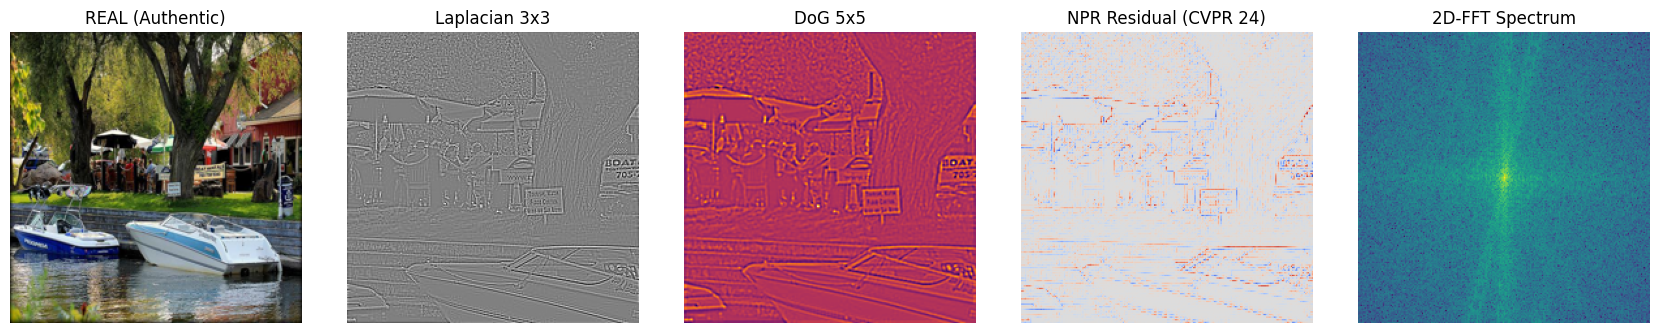

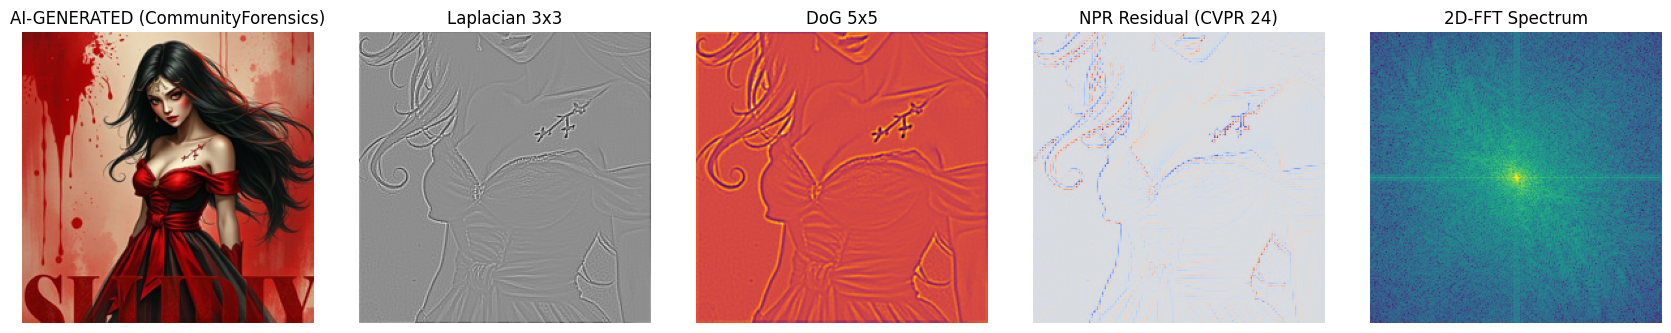

In [ ]:
sample_ai_row = df_dataset[df_dataset['label'] == 0].iloc[0]
sample_real_row = df_dataset[df_dataset['label'] == 1].iloc[0]

def inspect_forensic_signals(pil_img, title_prefix='Sample'):
    model.eval()
    t_img = eval_transform(pil_img).unsqueeze(0).to(device)
    with torch.no_grad():
        f_bank = model.forensic_bank(t_img)[0]
        lap3_vis = f_bank[0:3].mean(dim=0).cpu().numpy()
        dog_vis = f_bank[6:9].mean(dim=0).cpu().numpy()
        npr_vis = f_bank[12:15].mean(dim=0).cpu().numpy()
        fft_mag = torch.log(torch.abs(torch.fft.fftshift(torch.fft.fft2(t_img, norm='ortho'))) + 1e-6)[0].mean(dim=0).cpu().numpy()

    fig, axes = plt.subplots(1, 5, figsize=(17, 3.3))
    axes[0].imshow(pil_img.resize((IMG_SIZE, IMG_SIZE)))
    axes[0].set_title(title_prefix)
    axes[1].imshow(lap3_vis, cmap='gray')
    axes[1].set_title('Laplacian 3x3')
    axes[2].imshow(dog_vis, cmap='inferno')
    axes[2].set_title('DoG 5x5')
    axes[3].imshow(npr_vis, cmap='coolwarm')
    axes[3].set_title('NPR Residual (CVPR 24)')
    axes[4].imshow(fft_mag, cmap='viridis')
    axes[4].set_title('2D-FFT Spectrum')
    for ax in axes:
        ax.axis('off')
    plt.tight_layout()
    plt.show()

inspect_forensic_signals(Image.open(sample_real_row['image_path']).convert('RGB'), 'REAL (Authentic)')
inspect_forensic_signals(Image.open(sample_ai_row['image_path']).convert('RGB'), 'AI-GENERATED (CommunityForensics)')

## 🚀 6. Pelatihan Terakselerasi AMP FP16 + Focal Loss (20 Epoch)

Menyimpan bobot terbaik langsung sebagai `best_aiforensicnet_v4_cf.pth` (`model.state_dict()`) yang otomatis dikenali oleh `app.py`.

In [ ]:
EPOCHS = 12
PATIENCE = 4  # Early stopping jika Val F1 tidak naik selama 4 epoch
LEARNING_RATE = 5e-4
WEIGHT_DECAY = 1e-4
BEST_MODEL_PATH = 'best_aiforensicnet_v4_cf.pth'

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, label_smoothing=0.05):
        super().__init__()
        self.gamma = gamma
        self.label_smoothing = label_smoothing

    def forward(self, inputs, targets):
        ce = F.cross_entropy(inputs, targets, label_smoothing=self.label_smoothing, reduction='none')
        pt = torch.exp(-ce)
        return (((1.0 - pt) ** self.gamma) * ce).mean()

criterion = FocalLoss(gamma=2.0, label_smoothing=0.05)
optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)
use_amp = (device.type == 'cuda')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp)

best_val_f1 = 0.0
no_improve = 0
start_time = time.time()
print(f'[*] Memulai Pelatihan AIForensicNetV4 pada CommunityForensics (Maks {EPOCHS} Epoch, Early Stopping Patience={PATIENCE})...\n')

for epoch in range(1, EPOCHS + 1):
    model.train()
    running_loss = 0.0
    train_preds, train_targets = [], []

    pbar = tqdm(train_loader, desc=f'Epoch {epoch:02d}/{EPOCHS:02d} [Train]', leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.cuda.amp.autocast(enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        train_preds.extend(outputs.argmax(dim=1).cpu().numpy())
        train_targets.extend(labels.cpu().numpy())
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    epoch_train_loss = running_loss / len(train_df)
    epoch_train_acc = (np.array(train_preds) == np.array(train_targets)).mean() * 100

    model.eval()
    val_loss = 0.0
    val_preds, val_targets = [], []
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)
            with torch.cuda.amp.autocast(enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            val_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            val_targets.extend(labels.cpu().numpy())

    epoch_val_loss = val_loss / len(val_df)
    epoch_val_acc = (np.array(val_preds) == np.array(val_targets)).mean() * 100
    epoch_val_f1 = f1_score(val_targets, val_preds, average='macro') * 100
    scheduler.step()

    saved_marker = ''
    if epoch_val_f1 > best_val_f1:
        best_val_f1 = epoch_val_f1
        no_improve = 0
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        saved_marker = '==> [CHECKPOINT TERSIMPAN]'
    else:
        no_improve += 1

    print(f'Epoch {epoch:02d}/{EPOCHS:02d} | '
          f'Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.2f}% | '
          f'Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}% | '
          f'Val F1: {epoch_val_f1:.2f}% {saved_marker}')

    if no_improve >= PATIENCE:
        print(f'\n[!] Early Stopping aktif: Val F1 tidak meningkat selama {PATIENCE} epoch berturut-turut.')
        break

print('=' * 65)
print(f'Pelatihan Selesai dalam {(time.time() - start_time)/60:.2f} menit!')
print(f'Checkpoint Siap Pakai di app.py: {BEST_MODEL_PATH} (Best Val F1: {best_val_f1:.2f}%)')
print('=' * 65)

[*] Memulai Pelatihan AIForensicNetV4 pada CommunityForensics (Maks 12 Epoch, Early Stopping Patience=4)...



Epoch 01/12 [Train]:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 01/12 | Train Loss: 0.1445 | Train Acc: 72.10% | Val Loss: 0.1275 | Val Acc: 75.67% | Val F1: 75.52% ==> [CHECKPOINT TERSIMPAN]


Epoch 02/12 [Train]:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 02/12 | Train Loss: 0.1307 | Train Acc: 75.40% | Val Loss: 0.1252 | Val Acc: 76.86% | Val F1: 76.83% ==> [CHECKPOINT TERSIMPAN]


...

Epoch 10/12 | Train Loss: 0.0947 | Train Acc: 84.62% | Val Loss: 0.0807 | Val Acc: 86.59% | Val F1: 86.59% ==> [CHECKPOINT TERSIMPAN]


Epoch 11/12 [Train]:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 11/12 | Train Loss: 0.0928 | Train Acc: 84.63% | Val Loss: 0.0811 | Val Acc: 86.59% | Val F1: 86.59% ==> [CHECKPOINT TERSIMPAN]


Epoch 12/12 [Train]:   0%|          | 0/242 [00:00<?, ?it/s]

Epoch 12/12 | Train Loss: 0.0927 | Train Acc: 84.62% | Val Loss: 0.0791 | Val Acc: 87.01% | Val F1: 87.01% ==> [CHECKPOINT TERSIMPAN]
Pelatihan Selesai dalam 53.69 menit!
Checkpoint Siap Pakai di app.py: best_aiforensicnet_v4_cf.pth (Best Val F1: 87.01%)


## 📊 7. Evaluasi Test Set Independen (dengan Test-Time Augmentation / TTA)

Evaluasi Test Set (TTA):   0%|          | 0/31 [00:00<?, ?it/s]

LAPORAN KLASIFIKASI PADA TEST SET INDEPENDEN:
                  precision    recall  f1-score   support

AI-Generated (0)     0.9042    0.8516    0.8771       997
        Real (1)     0.8511    0.9038    0.8767       936

        accuracy                         0.8769      1933
       macro avg     0.8776    0.8777    0.8769      1933
    weighted avg     0.8785    0.8769    0.8769      1933

Akurasi Test Set : 87.69%
Macro F1-Score   : 87.69%
ROC-AUC Score    : 94.86%


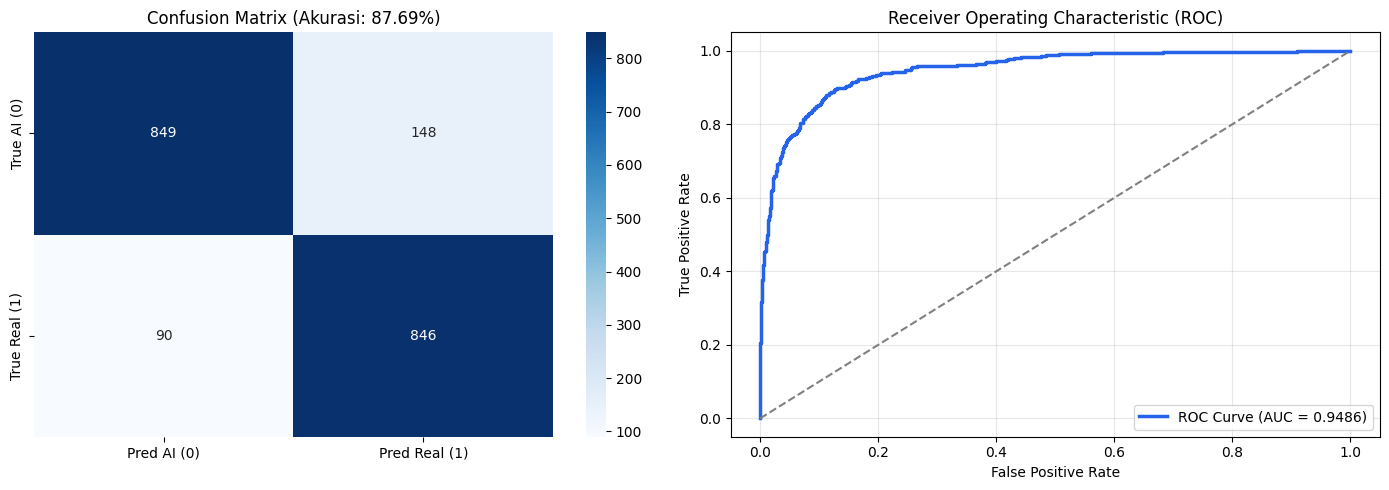

In [ ]:
model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.eval()

test_preds, test_targets, test_probs_real = [], [], []

with torch.no_grad():
    for images, labels in tqdm(test_loader, desc='Evaluasi Test Set (TTA)'):
        images = images.to(device)
        images_flip = torch.flip(images, dims=[3])
        with torch.cuda.amp.autocast(enabled=use_amp):
            probs_orig = torch.softmax(model(images), dim=1)
            probs_flip = torch.softmax(model(images_flip), dim=1)
            probs = (probs_orig + probs_flip) / 2.0

        test_probs_real.extend(probs[:, 1].cpu().numpy())
        test_preds.extend(probs.argmax(dim=1).cpu().numpy())
        test_targets.extend(labels.numpy())

test_targets = np.array(test_targets)
test_preds = np.array(test_preds)
test_probs_real = np.array(test_probs_real)

print('=' * 65)
print('LAPORAN KLASIFIKASI PADA TEST SET INDEPENDEN:')
print('=' * 65)
print(classification_report(test_targets, test_preds, target_names=['AI-Generated (0)', 'Real (1)'], digits=4))

test_acc = (test_targets == test_preds).mean() * 100
test_f1 = f1_score(test_targets, test_preds, average='macro') * 100
test_auc = roc_auc_score(test_targets, test_probs_real) * 100
print(f'Akurasi Test Set : {test_acc:.2f}%')
print(f'Macro F1-Score   : {test_f1:.2f}%')
print(f'ROC-AUC Score    : {test_auc:.2f}%')
print('=' * 65)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cm = confusion_matrix(test_targets, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred AI (0)', 'Pred Real (1)'], yticklabels=['True AI (0)', 'True Real (1)'])
axes[0].set_title(f'Confusion Matrix (Akurasi: {test_acc:.2f}%)')

fpr, tpr, _ = roc_curve(test_targets, test_probs_real)
axes[1].plot(fpr, tpr, color='#2563EB', lw=2.5, label=f'ROC Curve (AUC = {test_auc/100:.4f})')
axes[1].plot([0, 1], [0, 1], color='gray', linestyle='--')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc='lower right')
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 💾 8. Unduh Bobot Model untuk `app.py`

Simpan `best_aiforensicnet_v4_cf.pth` ke folder proyek Anda. `app.py` akan langsung memuatnya sebagai model utama **AIForensicNet V4 (Tri-Stream SOTA)**.

In [ ]:
from google.colab import files
if os.path.exists(BEST_MODEL_PATH):
    files.download(BEST_MODEL_PATH)
else:
    print(f'[!] File {BEST_MODEL_PATH} tidak ditemukan!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>